Cell 1: Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import tensorflow as tf
from tensorflow.keras import layers, Model, Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import KLDivergence


# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

sns.set_theme(style="whitegrid")
FEATURE_MATRIX_PATH = "D:\Project\Customer-segmentation\data\cleanCustomerFeature.csv"

<>:22: SyntaxWarning: invalid escape sequence '\P'
<>:22: SyntaxWarning: invalid escape sequence '\P'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33448\1810357339.py:22: SyntaxWarning: invalid escape sequence '\P'
  FEATURE_MATRIX_PATH = "D:\Project\Customer-segmentation\data\cleanCustomerFeature.csv"


Cell 2: Load Data & Standardize Features

In [2]:
# Load feature matrix from Notebook 02
df = pd.read_csv(FEATURE_MATRIX_PATH)

# Select log-transformed behavioral features
log_feature_cols = [col for col in df.columns if col.endswith('_log')]
X_raw = df[log_feature_cols].values

# Standardize features (Mean=0, Std=1) for neural networks & distance-based clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Dataset ready: {X_scaled.shape[0]} customers across {X_scaled.shape[1]} log-scaled features.")
print(log_feature_cols)

Dataset ready: 4332 customers across 7 log-scaled features.
['Recency_log', 'Frequency_log', 'Monetary_log', 'TotalQuantity_log', 'TotalItems_log', 'AvgOrderValue_log', 'AvgInterpurchaseDays_log']


Cell 3: Evaluation Metrics Utility Function

In [3]:
def evaluate_clustering(model_name, X_space, labels):
    """Computes Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index."""
    n_clusters = len(np.unique(labels))
    if n_clusters < 2:
        return None
    
    sil = silhouette_score(X_space, labels)
    db = davies_bouldin_score(X_space, labels)
    ch = calinski_harabasz_score(X_space, labels)
    
    return {
        "Model": model_name,
        "Clusters (K)": n_clusters,
        "Silhouette Score (↑)": round(sil, 4),
        "Davies-Bouldin Index (↓)": round(db, 4),
        "Calinski-Harabasz Index (↑)": round(ch, 2)
    }

results_list = []

Cell 4: Model 1 — Traditional Baseline: K-Means on Raw Features

In [4]:
# K-Means directly on standardized features (as cited in literature [3, 5, 10])
for k in [3, 4, 5]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    res = evaluate_clustering(f"Baseline: K-Means (K={k})", X_scaled, labels)
    results_list.append(res)

pd.DataFrame(results_list)

,Model,Clusters (K),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,Baseline: K-Means (K=3),3,0.3080,1.1852,2575.33
1,Baseline: K-Means (K=4),4,0.3139,1.1867,2088.46
2,Baseline: K-Means (K=5),5,0.2729,1.2552,1875.55


Cell 5: Model 2 — Linear Dimensionality Reduction: PCA + K-Means

In [5]:
# Linear compression to 3 dimensions before clustering
pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

for k in [3, 4, 5]:
    kmeans_pca = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_pca = kmeans_pca.fit_predict(X_pca)
    res = evaluate_clustering(f"PCA + K-Means (K={k})", X_pca, labels_pca)
    results_list.append(res)

pd.DataFrame(results_list)

,Model,Clusters (K),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,Baseline: K-Means (K=3),3,0.3080,1.1852,2575.33
1,Baseline: K-Means (K=4),4,0.3139,1.1867,2088.46
2,Baseline: K-Means (K=5),5,0.2729,1.2552,1875.55
3,PCA + K-Means (K=3),3,0.3309,1.0649,3256.16
4,PCA + K-Means (K=4),4,0.3422,1.0220,2759.19
5,PCA + K-Means (K=5),5,0.3040,1.0933,2513.68


Cell 6: Model 3 — Autoencoder Latent Embeddings + K-Means (Proposed Framework)

In [6]:
input_dim = X_scaled.shape[1]
latent_dim = 3  # Bottleneck embedding size

# Build Encoder
encoder_input = layers.Input(shape=(input_dim,), name="Encoder_Input")
x = layers.Dense(16, activation="relu")(encoder_input)
x = layers.BatchNormalization()(x)
x = layers.Dense(8, activation="relu")(x)
latent_bottleneck = layers.Dense(latent_dim, activation="linear", name="Latent_Space")(x)

encoder = Model(inputs=encoder_input, outputs=latent_bottleneck, name="Encoder")

# Build Decoder
decoder_input = layers.Input(shape=(latent_dim,), name="Decoder_Input")
y = layers.Dense(8, activation="relu")(decoder_input)
y = layers.Dense(16, activation="relu")(y)
reconstructed_output = layers.Dense(input_dim, activation="linear")(y)

decoder = Model(inputs=decoder_input, outputs=reconstructed_output, name="Decoder")

# Build Full Autoencoder
autoencoder_output = decoder(encoder(encoder_input))
autoencoder = Model(inputs=encoder_input, outputs=autoencoder_output, name="Autoencoder")

autoencoder.compile(optimizer=Adam(learning_rate=0.001), loss="mse")

# Train Autoencoder
history = autoencoder.fit(
    X_scaled, X_scaled,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    verbose=0
)

# Extract Latent Customer Embeddings
embeddings = encoder.predict(X_scaled)

# Perform K-Means on Latent Space
for k in [3, 4, 5]:
    kmeans_ae = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_ae = kmeans_ae.fit_predict(embeddings)
    res = evaluate_clustering(f"Autoencoder + K-Means (K={k})", embeddings, labels_ae)
    results_list.append(res)

pd.DataFrame(results_list)

136/136 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Model,Clusters (K),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,Baseline: K-Means (K=3),3,0.3080,1.1852,2575.33
1,Baseline: K-Means (K=4),4,0.3139,1.1867,2088.46
2,Baseline: K-Means (K=5),5,0.2729,1.2552,1875.55
3,PCA + K-Means (K=3),3,0.3309,1.0649,3256.16
4,PCA + K-Means (K=4),4,0.3422,1.0220,2759.19
5,PCA + K-Means (K=5),5,0.3040,1.0933,2513.68
6,Autoencoder + K-Means (K=3),3,0.4283,0.9076,5713.96
7,Autoencoder + K-Means (K=4),4,0.3671,1.0656,4759.29
8,Autoencoder + K-Means (K=5),5,0.2979,1.2323,4214.21


Cell 7: Model 4 — Deep Embedded Clustering (DEC) Refinement

In [7]:

class ClusteringLayer(layers.Layer):
    """Custom clustering layer that computes Student's t-distribution kernel."""
    def __init__(self, n_clusters=4, weights=None, alpha=1.0, **kwargs):
        super(ClusteringLayer, self).__init__(**kwargs)
        self.n_clusters = n_clusters
        self.alpha = alpha
        self.initial_weights = weights

    def build(self, input_shape):
        self.clusters = self.add_weight(
            shape=(self.n_clusters, input_shape[1]),
            initializer="glorot_uniform",
            name="cluster_centers"
        )
        if self.initial_weights is not None:
            self.set_weights(self.initial_weights)
        self.built = True

    def call(self, inputs):
        # q_ij = (1 + ||z_i - u_j||^2 / alpha) ^ -((alpha+1)/2)
        q = 1.0 / (1.0 + (tf.reduce_sum(tf.square(tf.expand_dims(inputs, axis=1) - self.clusters), axis=2) / self.alpha))
        q **= (self.alpha + 1.0) / 2.0
        q = tf.transpose(tf.transpose(q) / tf.reduce_sum(q, axis=1))
        return q

# Initialize DEC with K=3
k_opt = (3,4,5)
for k in k_opt:
    kmeans_init = KMeans(n_clusters=k, random_state=42, n_init=10)
    init_labels = kmeans_init.fit_predict(embeddings)
    cluster_centers_init = kmeans_init.cluster_centers_

    # Construct DEC Model
    clustering_output = ClusteringLayer(n_clusters=k, weights=[cluster_centers_init], name="DEC_Layer")(encoder.output)
    dec_model = Model(inputs=encoder.input, outputs=clustering_output)

    # Fix: Use KLDivergence() object directly to avoid version identifier string issues
    dec_model.compile(optimizer=Adam(learning_rate=0.0001), loss=KLDivergence())

    # DEC Target Distribution Function
    def target_distribution(q):
        weight = q ** 2 / q.sum(0)
        return (weight.T / weight.sum(1)).T

    # DEC Fine-Tuning Loop
    q = dec_model.predict(X_scaled, verbose=0)
    p = target_distribution(q)
    dec_model.fit(X_scaled, p, epochs=30, batch_size=32, verbose=0)

    # Extract DEC Clusters
    q_final = dec_model.predict(X_scaled, verbose=0)
    dec_labels = q_final.argmax(axis=1)

    res = evaluate_clustering(f"DEC (K={k})", embeddings, dec_labels)
    results_list.append(res)

print("DEC Model Trained & Evaluated Successfully!")


DEC Model Trained & Evaluated Successfully!


Cell 8: Consolidate & Export Benchmark Results Table

In [8]:
# Convert to DataFrame
benchmark_df = pd.DataFrame(results_list)
print("=== MODEL COMPARISON RESULTS ===")
display(benchmark_df)

# Save results for paper / presentation
benchmark_df.to_csv("D:\\Project\\Customer-segmentation\\results.csv", index=False)

=== MODEL COMPARISON RESULTS ===


,Model,Clusters (K),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,Baseline: K-Means (K=3),3,0.3080,1.1852,2575.33
1,Baseline: K-Means (K=4),4,0.3139,1.1867,2088.46
2,Baseline: K-Means (K=5),5,0.2729,1.2552,1875.55
3,PCA + K-Means (K=3),3,0.3309,1.0649,3256.16
4,PCA + K-Means (K=4),4,0.3422,1.0220,2759.19
5,PCA + K-Means (K=5),5,0.3040,1.0933,2513.68
6,Autoencoder + K-Means (K=3),3,0.4283,0.9076,5713.96
7,Autoencoder + K-Means (K=4),4,0.3671,1.0656,4759.29
8,Autoencoder + K-Means (K=5),5,0.2979,1.2323,4214.21
9,DEC (K=3),3,0.4219,0.9260,5697.72


Autoencoder + k-means(k=3) performs the best

Cell 9: Assign Final Cluster Labels & Export Profiled Customers

In [ ]:
OPTIMAL_K = 3
# 1. Fit K-Means with K=3 on Autoencoder Latent Embeddings
best_kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
final_cluster_labels = best_kmeans.fit_predict(embeddings)

# 2. Assign cluster labels back to the DataFrame
df['Cluster'] = final_cluster_labels

# 3. Identify available RFM columns (handles both raw and log-transformed column names safely)
rfm_cols = {}
for col in ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue']:
    if col in df.columns:
        rfm_cols[col] = 'mean'
    elif f'{col}_log' in df.columns:
        rfm_cols[f'{col}_log'] = 'mean'

# 4. Generate Cluster Profile Summary
cluster_summary = df.groupby('Cluster').agg(rfm_cols).round(2)
cluster_summary['Customer_Count'] = df.groupby('Cluster').size()

print("=== SEGMENT PERSONA PROFILE SUMMARY (K=4) ===")
print(cluster_summary)

output_path = "D:\\Project\\Customer-segmentation\\segmented_customers.csv"
df.to_csv(output_path, index=False)
print(f"\nFinal customer segmentations exported successfully to: {output_path}")

=== SEGMENT PERSONA PROFILE SUMMARY (K=4) ===
         Recency  Frequency  Monetary  AvgOrderValue  Customer_Count
Cluster                                                             
0          35.16      11.57   6483.07         253.71             914
1         155.47       1.05    362.38          42.06            1563
2          68.27       3.27    936.40          57.55            1855

Final customer segmentations exported successfully to: D:\Project\Customer-segmentation\segmented_customers.csv


Cell 10: Import Graph libraries

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

Cell 11: Inilalize Graph df

In [11]:
graph_df = benchmark_df.copy()

Cell 12: All Models Across Evaluation Metrics

C:\Users\ASUS\AppData\Local\Temp\ipykernel_33448\1044850671.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33448\1044850671.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33448\1044850671.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


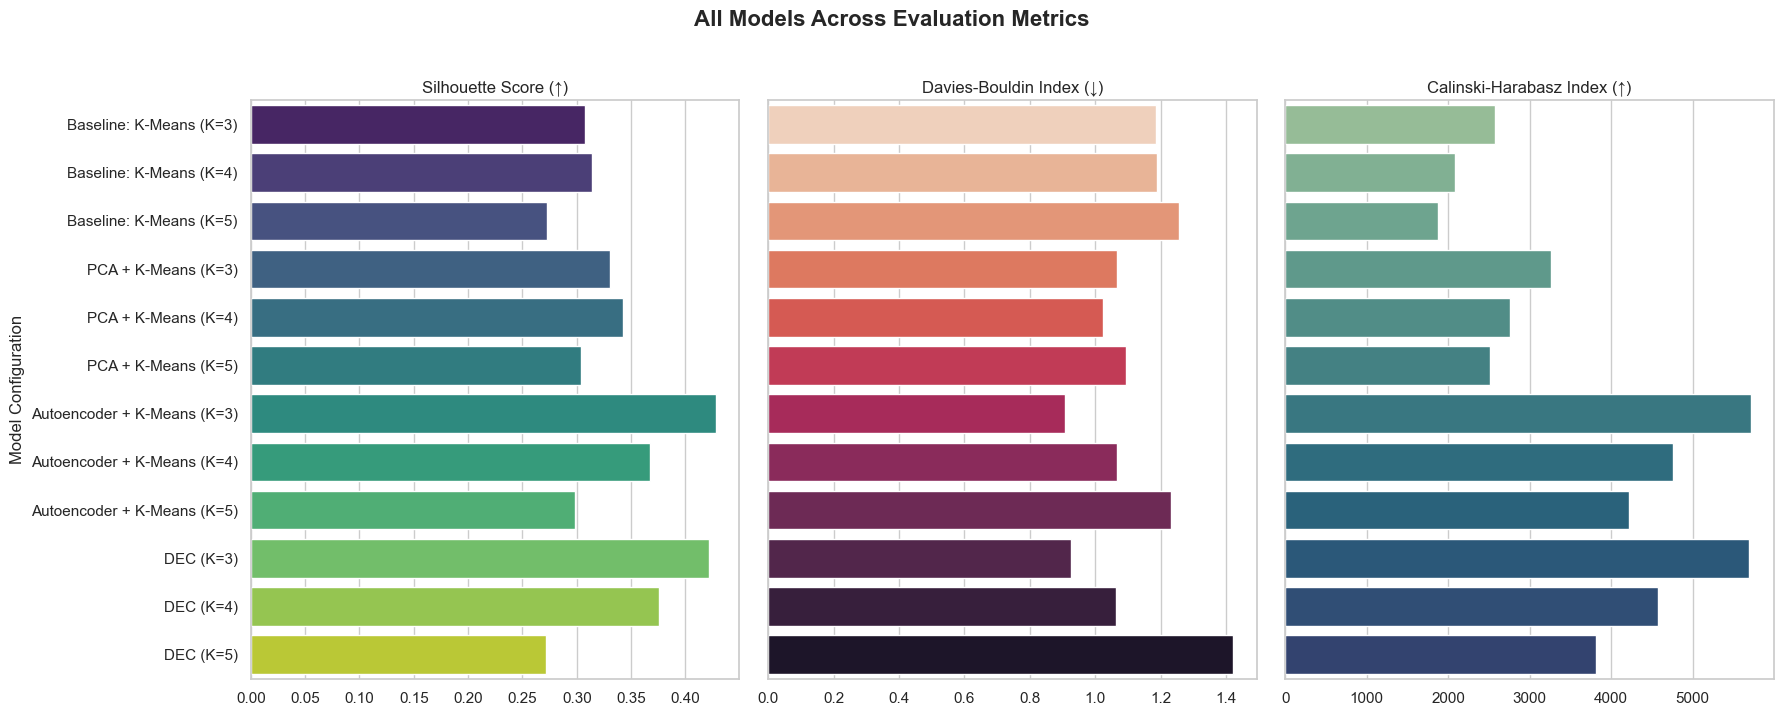

In [12]:
# 2. Set up a 1-row, 3-column figure grid
fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)
sns.set_theme(style='whitegrid')

# Panel 1: Silhouette Score (Higher is better)
sns.barplot(
    data=graph_df, x='Silhouette Score (↑)', y='Model', ax=axes[0], palette='viridis'
)
axes[0].set_title('Silhouette Score (↑)', fontsize=12)
axes[0].set_xlabel('')
axes[0].set_ylabel('Model Configuration', fontsize=12)

# Panel 2: Davies-Bouldin Index (Lower is better)
sns.barplot(
    data=graph_df,
    x='Davies-Bouldin Index (↓)',
    y='Model',
    ax=axes[1],
    palette='rocket_r',
)
axes[1].set_title('Davies-Bouldin Index (↓)', fontsize=12)
axes[1].set_xlabel('')
axes[1].set_ylabel('')

# Panel 3: Calinski-Harabasz Index (Higher is better)
sns.barplot(
    data=graph_df,
    x='Calinski-Harabasz Index (↑)',
    y='Model',
    ax=axes[2],
    palette='crest',
)
axes[2].set_title('Calinski-Harabasz Index (↑)', fontsize=12)
axes[2].set_xlabel('')
axes[2].set_ylabel('')

# Overall layout adjustments
plt.suptitle(
    'All Models Across Evaluation Metrics',
    fontsize=16,
    weight='bold',
    y=1.02,
)
plt.tight_layout()
plt.savefig(r"D:\Project\Customer-segmentation\graphs\allModelComparison.png", dpi=300, bbox_inches='tight')


plt.show()

Cell 13: Customer Segments Visualized in 2D PCA Feature Space

<>:5: SyntaxWarning: invalid escape sequence '\P'
<>:5: SyntaxWarning: invalid escape sequence '\P'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33448\1126209571.py:5: SyntaxWarning: invalid escape sequence '\P'
  temp_df = pd.read_csv("D:\Project\Customer-segmentation\segmented_customers.csv")


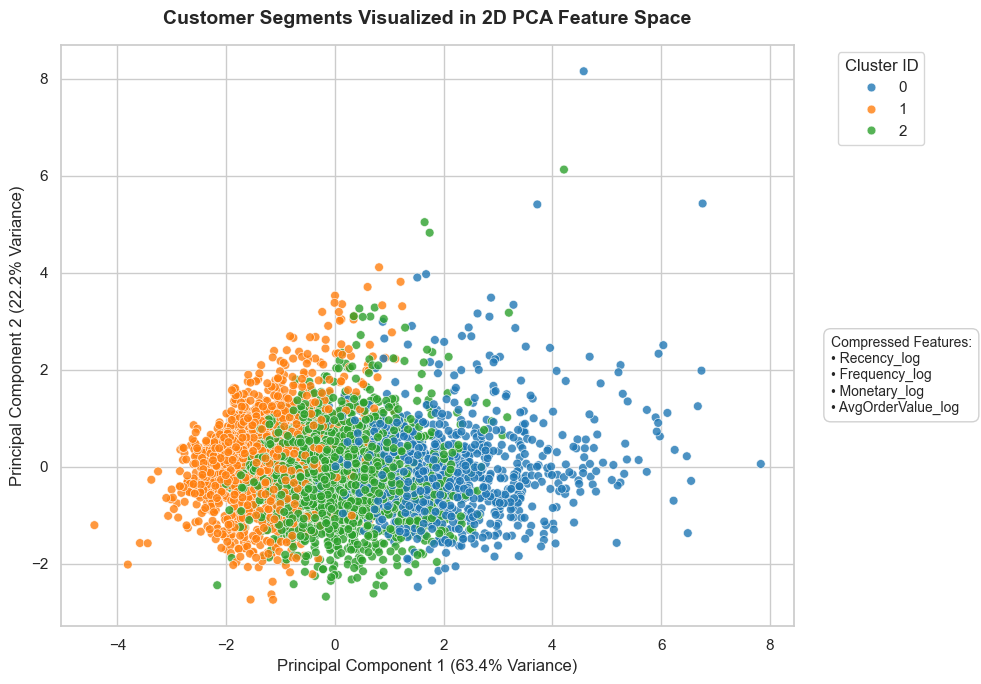

In [13]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


temp_df = pd.read_csv("D:\Project\Customer-segmentation\segmented_customers.csv")

feature_cols = ['Recency_log', 'Frequency_log', 'Monetary_log', 'AvgOrderValue_log']

X = temp_df[feature_cols].values

# Standardize and project features into 2D using PCA for visualization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=42)
coords_2d = pca.fit_transform(X_scaled)

temp_df['PCA1'] = coords_2d[:, 0]
temp_df['PCA2'] = coords_2d[:, 1]

# Create the scatter plot
plt.figure(figsize=(10, 7))
sns.set_theme(style='whitegrid')

sns.scatterplot(
    data=temp_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='tab10',
    alpha=0.8,
    s=40,
    edgecolor='w',
    linewidth=0.5,
)

# Formatting and Labels
plt.title(
    'Customer Segments Visualized in 2D PCA Feature Space',
    fontsize=14,
    weight='bold',
    pad=15,
)
plt.xlabel(
    f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)',
    fontsize=12,
)
plt.ylabel(
    f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)',
    fontsize=12,
)
features_text = "Compressed Features:\n" + "\n".join(
    [f"• {col}" for col in feature_cols])

leg = plt.legend(
    title="Cluster ID",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=True,
)

plt.text(
    1.05,
    0.5,
    features_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="0.8",
        alpha=0.9,
    ),
)
plt.tight_layout()
plt.savefig(r"D:\Project\Customer-segmentation\graphs\2dPCAscatterPlot", dpi=300, bbox_inches='tight')


plt.show()

Cell 14: Model Evaluation Metrics

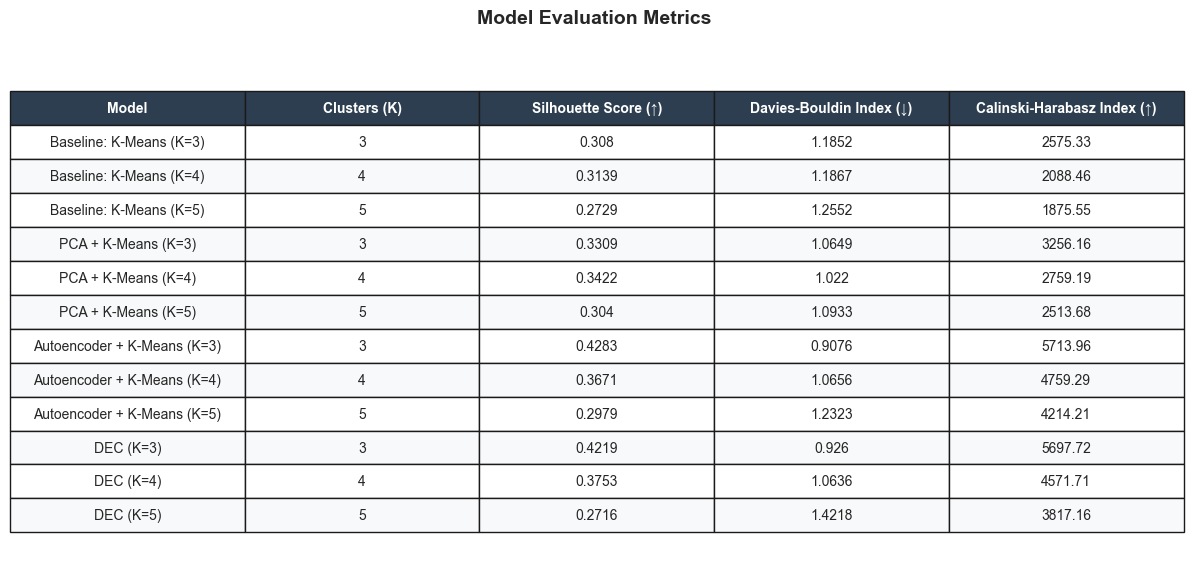

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

fig, ax = plt.subplots(figsize=(12, 6))
ax.axis('off')
ax.axis('tight')
df_results = benchmark_df.copy()
# Create the table visual
table = ax.table(
    cellText=df_results.values,
    colLabels=df_results.columns,
    cellLoc='center',
    loc='center',
)

# Style table properties
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)  # Adjust width and height scaling

# Color header row differently
for key, cell in table.get_celld().items():
  if key[0] == 0:
    cell.set_facecolor('#2c3e50')
    cell.set_text_props(color='white', weight='bold')
  else:
    cell.set_facecolor('#f8f9fa' if key[0] % 2 == 0 else '#ffffff')

plt.title(
    'Model Evaluation Metrics ',
    fontsize=14,
    weight='bold',
    pad=20,
)
plt.tight_layout()

# Save image for report
plt.savefig(
    r"D:\Project\Customer-segmentation\graphs\allModelEvaluation.png",
    dpi=300,
    bbox_inches='tight',
)
plt.show()

Ce;; 15: 

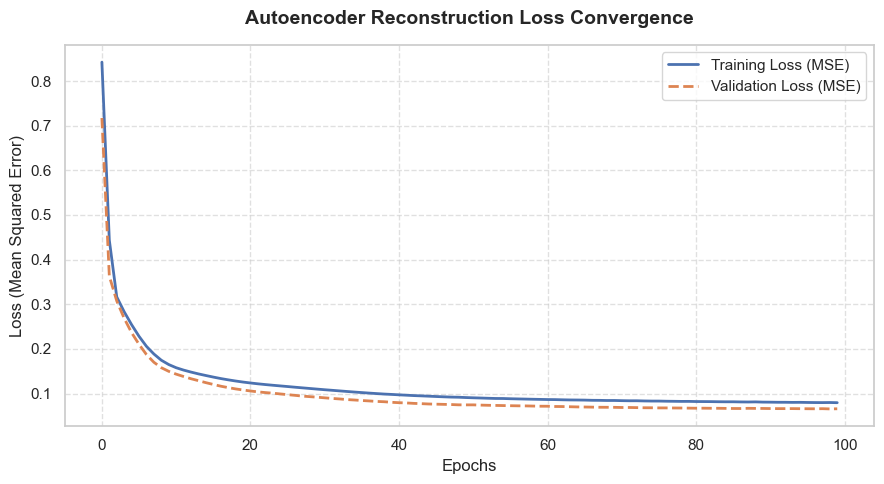

In [15]:
# In[]: Plot Autoencoder Training & Validation Loss
plt.figure(figsize=(9, 5))
plt.plot(history.history['loss'], label='Training Loss (MSE)', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', linewidth=2, linestyle='--')
plt.title('Autoencoder Reconstruction Loss Convergence', fontsize=14, weight='bold', pad=15)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss (Mean Squared Error)', fontsize=12)
plt.legend(frameon=True, fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(r"D:\Project\Customer-segmentation\graphs\autoencoderLossCurve.png", dpi=300, bbox_inches='tight')
plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_33448\2824744723.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=temp_df, x='Cluster', y=col, ax=axes[i], palette='Set2', width=0.5, fliersize=3)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33448\2824744723.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=temp_df, x='Cluster', y=col, ax=axes[i], palette='Set2', width=0.5, fliersize=3)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33448\2824744723.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=temp_df, x='Cluster', y=col, ax=ax

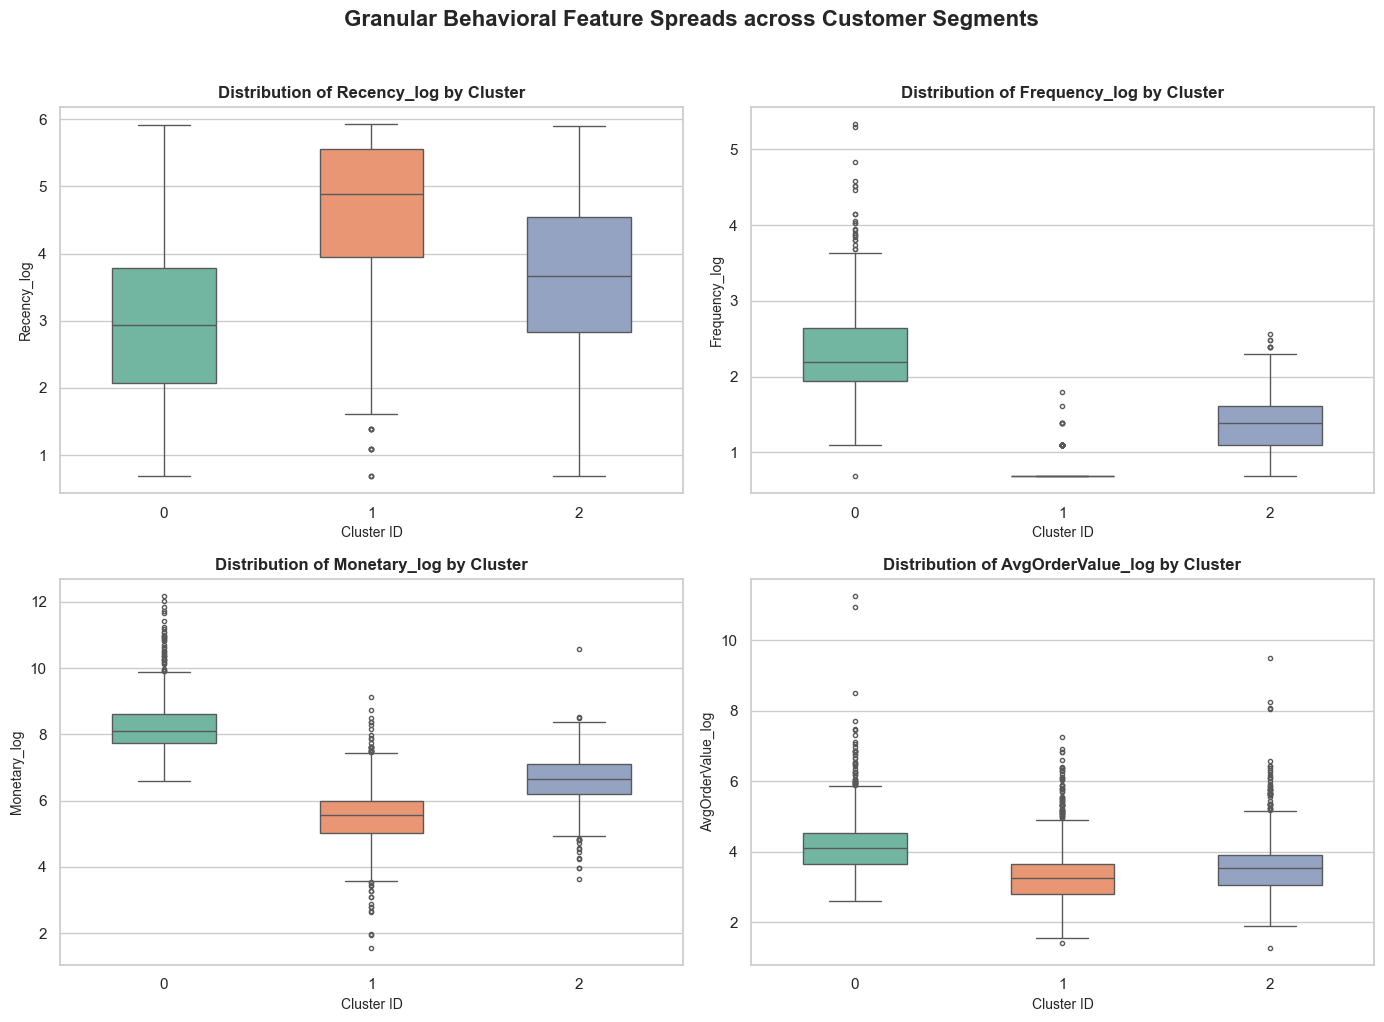

In [16]:
# In[]: Behavioral Feature Distributions per Cluster
temp_df = pd.read_csv(r"D:\Project\Customer-segmentation\segmented_customers.csv")
feature_cols = ['Recency_log', 'Frequency_log', 'Monetary_log', 'AvgOrderValue_log']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.boxplot(data=temp_df, x='Cluster', y=col, ax=axes[i], palette='Set2', width=0.5, fliersize=3)
    axes[i].set_title(f'Distribution of {col} by Cluster', fontsize=12, weight='bold')
    axes[i].set_xlabel('Cluster ID', fontsize=10)
    axes[i].set_ylabel(col, fontsize=10)

plt.suptitle('Granular Behavioral Feature Spreads across Customer Segments', fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.savefig(r"D:\Project\Customer-segmentation\graphs\featureBoxplots.png", dpi=300, bbox_inches='tight')
plt.show()

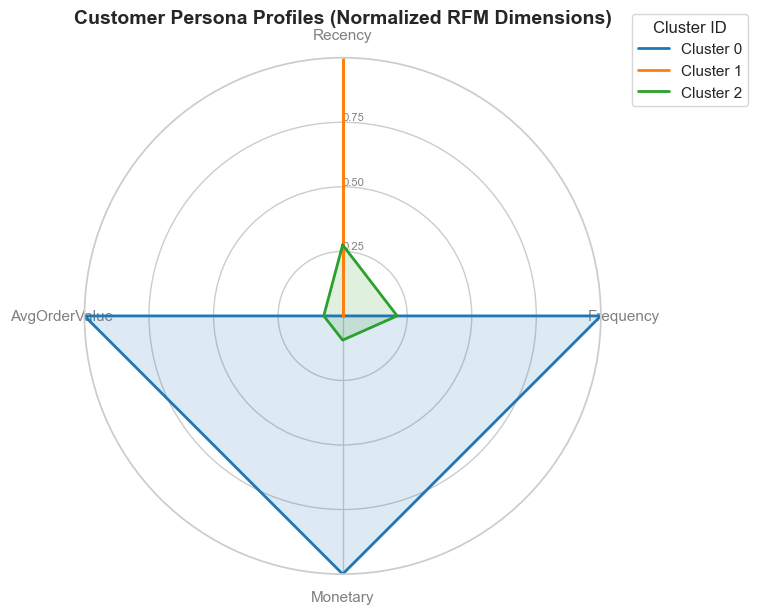

In [17]:
# In[]: Radar Chart for Customer Segment Personas
from math import pi

# Compute mean values and normalize them between 0 and 1 for the radar chart
cluster_means = temp_df.groupby('Cluster')[['Recency', 'Frequency', 'Monetary', 'AvgOrderValue']].mean()
normalized_means = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min())

categories = list(normalized_means.columns)
N = len(categories)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for idx, row in normalized_means.iterrows():
    values = row.values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=f'Cluster {idx}', color=colors[idx])
    ax.fill(angles, values, color=colors[idx], alpha=0.15)

ax.set_theta_offset(pi / 2)
ax.set_theta_direction(-1)
plt.xticks(angles[:-1], categories, color='grey', size=11)
ax.set_rlabel_position(0)
plt.yticks([0.25, 0.5, 0.75], ["0.25", "0.50", "0.75"], color="grey", size=8)
plt.ylim(0, 1)

plt.title('Customer Persona Profiles (Normalized RFM Dimensions)', fontsize=14, weight='bold', pad=25)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), title="Cluster ID")
plt.tight_layout()
plt.savefig(r"D:\Project\Customer-segmentation\graphs\radarChartPersonas.png", dpi=300, bbox_inches='tight')
plt.show()